# Fixed-Extractor Prompt Technique and Deep Behavior Analysis

This notebook reruns the main prompt-technique analysis and the deeper behavior-control analysis using the corrected result files:

- `results/gemma2-9b_fixextractor.jsonl`
- `results/llama3.1-8b_fixextractor.jsonl`
- `results/qwen2.5-7b_fixextractor.jsonl`

Why this notebook exists:

The original extractor only accepted fenced markdown code blocks. Some Llama 3.1 responses were plain Python code without fences, so they were incorrectly marked as `No code extracted`. The fixed extractor falls back to the full response and validates it with `ast.parse()`.

The goal is to answer two questions:

1. How do the main prompt-technique results change after fixing extraction?
2. Does the tone effect still disappear after controlling for output length, code-only behavior, extraction/parsing validity, and runtime?

## 1. Imports and Paths

All outputs from this notebook are written to:

`analysis_outputs/fixed_extractor/`

In [2]:
from __future__ import annotations

import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
PROBLEMS_PATH = ROOT / "problems.csv"
PROMPT_MATRIX_PATH = ROOT / "prompt_matrix_prompt_template.08.csv"
RESULTS_DIR = ROOT / "results"
OUTPUT_DIR = ROOT / "analysis_outputs" / "fixed_extractor"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PATH = ROOT / "prompt_technique_effect_report_fixextractor.md"

print("ROOT:", ROOT)
print("OUTPUT_DIR:", OUTPUT_DIR)

ROOT: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset
OUTPUT_DIR: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs/fixed_extractor


## 2. Load Fixed-Extractor Results

The result files are joined with:

- prompt-template metadata from `prompt_matrix_prompt_template.08.csv`
- problem/test metadata from `problems.csv`

Each result `task_id` is parsed as `problem_id_template_id`.

In [3]:
def read_jsonl(path: Path) -> pd.DataFrame:
    rows = []
    with path.open("r", encoding="utf-8") as handle:
        for line_no, line in enumerate(handle, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                row = json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path} line {line_no}: {exc}") from exc
            row["source_file"] = path.name
            rows.append(row)
    return pd.DataFrame(rows)


def parse_result_task_id(value: object) -> tuple[int, int]:
    match = re.fullmatch(r"(\d+)_(\d+)", str(value))
    if not match:
        raise ValueError(f"Unexpected result task_id format: {value!r}")
    return int(match.group(1)), int(match.group(2))


def short_model_name(source_file: str, model_value: object = None) -> str:
    name = source_file.removesuffix("_fixextractor.jsonl")
    name = name.removesuffix("_final.jsonl")
    if name != source_file:
        return name
    if model_value is not None:
        return str(model_value).replace(":", "-")
    return source_file.removesuffix(".jsonl")


problems = pd.read_csv(PROBLEMS_PATH)
prompt_matrix = pd.read_csv(PROMPT_MATRIX_PATH).rename(columns={"ID": "template_id", "Role framing": "Role_framing"})
result_paths = sorted(RESULTS_DIR.glob("*_fixextractor.jsonl"))

if not result_paths:
    raise FileNotFoundError(f"No *_fixextractor.jsonl files found in {RESULTS_DIR}")

results = pd.concat([read_jsonl(path) for path in result_paths], ignore_index=True)
parsed_ids = results["task_id"].map(parse_result_task_id)
results["problem_id"] = parsed_ids.map(lambda pair: pair[0])
results["template_id"] = parsed_ids.map(lambda pair: pair[1])
results["model_short"] = [
    short_model_name(src, model)
    for src, model in zip(results["source_file"], results.get("model", pd.Series([None] * len(results))))
]

problem_meta = (
    problems.rename(columns={"task_id": "problem_id"})
    .sort_values(["problem_id", "category_id"])
    .drop_duplicates("problem_id")
    [["problem_id", "prompt", "test_cases", "challenge_test_list"]]
)

df = (
    results.merge(prompt_matrix, on="template_id", how="left", validate="many_to_one")
    .merge(problem_meta, on="problem_id", how="left", validate="many_to_one", suffixes=("", "_problem"))
)

print("Result files:", [p.name for p in result_paths])
print("Rows:", len(df))
print("Models:", sorted(df["model_short"].unique()))
print("Problems:", df["problem_id"].nunique())
print("Templates:", df["template_id"].nunique())
df.head(3)

Result files: ['gemma2-9b_fixextractor.jsonl', 'llama3.1-8b_fixextractor.jsonl', 'qwen2.5-7b_fixextractor.jsonl']
Rows: 2700
Models: ['gemma2-9b', 'llama3.1-8b', 'qwen2.5-7b']
Problems: 50
Templates: 18


,timestamp,model,task_id,passed,tests_passed,tests_total,errors,duration_seconds,prompt_tokens,completion_tokens,response_text,extracted_code,fixextractor_timestamp,fixextractor_version,original_passed,original_tests_passed,original_errors,original_extracted_code_empty,source_file,problem_id,template_id,model_short,Tone,Pressure,Role_framing,Format,ProblemID,Prompt,FinalPrompt,prompt,test_cases,challenge_test_list
0,2026-04-23T10:20:17.804264,gemma2:9b,1_1,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",10.820442,205,214,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",2026-04-30T17:11:55.899697,v1_ast_plain_response_fallback,False,6,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,1,1,gemma2-9b,neutral,NaN,no role,plaintext,1,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
1,2026-04-23T10:20:25.565780,gemma2:9b,1_2,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.693842,232,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",2026-04-30T17:11:55.900614,v1_ast_plain_response_fallback,False,6,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,1,2,gemma2-9b,neutral,NaN,no role,json,1,"{\n ""instruction"": ""You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Comp...",NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
2,2026-04-23T10:20:33.334104,gemma2:9b,1_3,False,6,7,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",7.700639,275,220,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of thr...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n """"""Calculates the maximum total reward in millions of VND for forming groups of three people w...",2026-04-30T17:11:55.900845,v1_ast_plain_response_fallback,False,6,"[Test failed: assert calculate_max_reward(10, 15, 500000) == 5 | Error: ]",False,gemma2-9b_fixextractor.jsonl,1,3,gemma2-9b,neutral,NaN,no role,xml,1,<prompt>\n<instruction>\nYou are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. ...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete

## 3. Derived Metrics

Performance metrics:

- `passed_int`: exact pass/fail as 0/1
- `tests_fraction`: fraction of unit tests passed

Behavior metrics:

- `completion_tokens`: output length
- `duration_seconds`: runtime
- `likely_code_only`: response mostly consists of extracted code
- `invalid_python_after_fix`: fixed extractor produced text that is not valid Python
- `extra_text_ratio`: share of response outside extracted code
- `fixed_extractor_changed`: whether this row had different extracted code after repair

In [4]:
def safe_len(value: object) -> int:
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))


def count_lines(value: object) -> int:
    if not isinstance(value, str) or not value.strip():
        return 0
    return len(value.splitlines())


def error_text(errors: object) -> str:
    if isinstance(errors, list):
        return "\n".join(map(str, errors))
    if pd.isna(errors):
        return ""
    return str(errors)


def classify_error(errors: object, extracted_code: object) -> str:
    text = error_text(errors).lower()
    code = extracted_code if isinstance(extracted_code, str) else ""
    if "response is not valid python" in text:
        return "invalid_python_response"
    if not code.strip():
        return "missing_or_empty_code"
    if not text.strip():
        return "none"
    if "not defined" in text:
        return "name_not_defined"
    if "syntax" in text or "invalid syntax" in text:
        return "syntax_error"
    if "timeout" in text or "timed out" in text:
        return "timeout"
    if "importerror" in text or "no module named" in text:
        return "import_error"
    if "assert" in text or "test failed" in text:
        return "wrong_answer"
    return "other_runtime"


df["passed_int"] = df["passed"].astype(bool).astype(int)
df["tests_passed"] = pd.to_numeric(df["tests_passed"], errors="coerce")
df["tests_total"] = pd.to_numeric(df["tests_total"], errors="coerce")
df["tests_fraction"] = np.where(df["tests_total"] > 0, df["tests_passed"] / df["tests_total"], np.nan)
df["prompt_tokens"] = pd.to_numeric(df["prompt_tokens"], errors="coerce")
df["completion_tokens"] = pd.to_numeric(df["completion_tokens"], errors="coerce")
df["duration_seconds"] = pd.to_numeric(df["duration_seconds"], errors="coerce")
df["total_tokens"] = df["prompt_tokens"] + df["completion_tokens"]

df["response_chars"] = df["response_text"].map(safe_len)
df["code_chars"] = df["extracted_code"].map(safe_len)
df["response_lines"] = df["response_text"].map(count_lines)
df["code_lines"] = df["extracted_code"].map(count_lines)
df["has_extracted_code"] = (df["code_chars"] > 0).astype(int)
df["extra_text_chars"] = (df["response_chars"] - df["code_chars"]).clip(lower=0)
df["extra_text_ratio"] = np.where(df["response_chars"] > 0, df["extra_text_chars"] / df["response_chars"], np.nan)
df["likely_code_only"] = ((df["has_extracted_code"] == 1) & (df["extra_text_ratio"] < 0.15)).astype(int)
df["error_text"] = df["errors"].map(error_text)
df["error_category"] = [classify_error(e, c) for e, c in zip(df["errors"], df["extracted_code"])]
df["invalid_python_after_fix"] = df["error_category"].eq("invalid_python_response").astype(int)
df["runtime_failure"] = df["error_category"].isin([
    "syntax_error", "name_not_defined", "import_error", "other_runtime", "timeout", "missing_or_empty_code", "invalid_python_response"
]).astype(int)
df["log_completion_tokens"] = np.log1p(df["completion_tokens"])
df["log_duration_seconds"] = np.log1p(df["duration_seconds"])
df["fixed_extractor_changed"] = df.get("original_extracted_code_empty", pd.Series(False, index=df.index)).astype(bool).astype(int)
df["pass_changed_after_fix"] = (df.get("original_passed", df["passed"]).astype(bool) != df["passed"].astype(bool)).astype(int)

technique_candidates = ["Tone", "Pressure", "Role_framing", "Format"]
technique_factors = []
for col in technique_candidates:
    if col in df.columns and df[col].dropna().nunique() > 1:
        technique_factors.append(col)
print("Technique factors:", technique_factors)

df.to_csv(OUTPUT_DIR / "joined_fixed_extractor_data.csv", index=False)
df[["model_short", "problem_id", "template_id", *technique_factors, "passed_int", "tests_fraction", "completion_tokens", "likely_code_only", "invalid_python_after_fix", "error_category"]].head()

Technique factors: ['Tone', 'Role_framing', 'Format']


,model_short,problem_id,template_id,Tone,Role_framing,Format,passed_int,tests_fraction,completion_tokens,likely_code_only,invalid_python_after_fix,error_category
0,gemma2-9b,1,1,neutral,no role,plaintext,0,0.857143,214,1,0,wrong_answer
1,gemma2-9b,1,2,neutral,no role,json,0,0.857143,220,1,0,wrong_answer
2,gemma2-9b,1,3,neutral,no role,xml,0,0.857143,220,1,0,wrong_answer
3,gemma2-9b,1,4,neutral,developer role,plaintext,0,0.857143,212,1,0,wrong_answer
4,gemma2-9b,1,5,neutral,developer role,json,0,0.857143,222,1,0,wrong_answer


## 4. Extractor Fix Impact

This shows how many outputs changed because of the fixed extractor.

The key result should be that Llama 3.1 improves because many plain-code responses were previously missed by the markdown-fence-only extractor.

In [5]:
extractor_impact = (
    df.groupby("model_short")
    .agg(
        runs=("task_id", "size"),
        original_pass_rate=("original_passed", lambda s: pd.Series(s).astype(bool).mean() if "original_passed" in df else np.nan),
        fixed_pass_rate=("passed_int", "mean"),
        original_passes=("original_passed", lambda s: int(pd.Series(s).astype(bool).sum()) if "original_passed" in df else np.nan),
        fixed_passes=("passed_int", "sum"),
        changed_extraction=("fixed_extractor_changed", "sum"),
        changed_pass=("pass_changed_after_fix", "sum"),
        invalid_python_after_fix=("invalid_python_after_fix", "sum"),
    )
    .reset_index()
)
extractor_impact.to_csv(OUTPUT_DIR / "extractor_fix_impact_by_model.csv", index=False)
extractor_impact.style.format({"original_pass_rate": "{:.1%}", "fixed_pass_rate": "{:.1%}"})

,model_short,runs,original_pass_rate,fixed_pass_rate,original_passes,fixed_passes,changed_extraction,changed_pass,invalid_python_after_fix
0,gemma2-9b,900,9.4%,9.4%,85,85,0,0,0
1,llama3.1-8b,900,3.9%,5.3%,35,48,97,13,3
2,qwen2.5-7b,900,13.4%,13.4%,121,121,3,0,3


## 5. Overall Model Performance

This is the corrected version of the original model-performance table.

In [6]:
model_summary = (
    df.groupby("model_short")
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        avg_tests_fraction=("tests_fraction", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python_after_fix", "mean"),
    )
    .reset_index()
    .sort_values("pass_rate", ascending=False)
)
model_summary.to_csv(OUTPUT_DIR / "model_summary.csv", index=False)
model_summary.style.format({
    "pass_rate": "{:.1%}", "avg_tests_fraction": "{:.1%}", "avg_duration_seconds": "{:.2f}",
    "avg_completion_tokens": "{:.0f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}"
})

,model_short,runs,pass_rate,avg_tests_fraction,avg_duration_seconds,avg_completion_tokens,code_only_rate,invalid_python_rate
2,qwen2.5-7b,900,13.4%,17.0%,18.59,653,26.7%,0.3%
0,gemma2-9b,900,9.4%,14.0%,19.56,601,25.9%,0.0%
1,llama3.1-8b,900,5.3%,8.9%,16.33,562,23.0%,0.3%


## 6. Main Prompt-Technique Summary

This reruns the original factor summaries for:

- tone
- role framing
- format

The most important table is the tone table.

In [7]:
def mean_ci(series: pd.Series, z: float = 1.96) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce").dropna()
    n = len(values)
    mean = values.mean() if n else np.nan
    se = values.std(ddof=1) / math.sqrt(n) if n > 1 else np.nan
    return pd.Series({"mean": mean, "ci_low": mean - z * se if n > 1 else np.nan, "ci_high": mean + z * se if n > 1 else np.nan, "n": n})

summary_metrics = ["passed_int", "tests_fraction", "duration_seconds", "completion_tokens", "likely_code_only", "extra_text_ratio", "invalid_python_after_fix"]
factor_summaries = []
for factor in technique_factors:
    for metric in summary_metrics:
        part = df.groupby(factor, dropna=False)[metric].apply(mean_ci).unstack().reset_index()
        part.insert(0, "factor", factor)
        part.insert(2, "metric", metric)
        factor_summaries.append(part)
factor_summary = pd.concat(factor_summaries, ignore_index=True)
factor_summary.to_csv(OUTPUT_DIR / "factor_summary.csv", index=False)

for factor in technique_factors:
    print(f"\n=== {factor} ===")
    display(factor_summary[factor_summary["factor"].eq(factor)].style.format({"mean": "{:.4f}", "ci_low": "{:.4f}", "ci_high": "{:.4f}"}))


=== Tone ===


,factor,Tone,metric,mean,ci_low,ci_high,n,Role_framing,Format
0,Tone,aggressive,passed_int,0.0833,0.0653,0.1014,900.000000,nan,nan
1,Tone,neutral,passed_int,0.1178,0.0967,0.1388,900.000000,nan,nan
2,Tone,polite,passed_int,0.0811,0.0633,0.0990,900.000000,nan,nan
3,Tone,aggressive,tests_fraction,0.1168,0.0972,0.1364,900.000000,nan,nan
4,Tone,neutral,tests_fraction,0.1694,0.1469,0.1919,900.000000,nan,nan
5,Tone,polite,tests_fraction,0.1130,0.0935,0.1325,900.000000,nan,nan
6,Tone,aggressive,duration_seconds,20.3969,19.9984,20.7953,900.000000,nan,nan
7,Tone,neutral,duration_seconds,12.6208,12.2567,12.9850,900.000000,nan,nan
8,Tone,polite,duration_seconds,21.4679,21.1154,21.8205,900.000000,nan,nan
9,Tone,aggressive,completion_tokens,686.7367,672.7107,700.7627,900.000000,nan,nan



=== Role_framing ===


,factor,Tone,metric,mean,ci_low,ci_high,n,Role_framing,Format
21,Role_framing,nan,passed_int,0.0933,0.0778,0.1089,1350.000000,developer role,nan
22,Role_framing,nan,passed_int,0.0948,0.0792,0.1104,1350.000000,no role,nan
23,Role_framing,nan,tests_fraction,0.1363,0.1194,0.1532,1350.000000,developer role,nan
24,Role_framing,nan,tests_fraction,0.1298,0.1130,0.1466,1350.000000,no role,nan
25,Role_framing,nan,duration_seconds,18.1606,17.7959,18.5253,1350.000000,developer role,nan
26,Role_framing,nan,duration_seconds,18.1631,17.7888,18.5375,1350.000000,no role,nan
27,Role_framing,nan,completion_tokens,605.4096,592.8878,617.9315,1350.000000,developer role,nan
28,Role_framing,nan,completion_tokens,604.9867,592.1607,617.8127,1350.000000,no role,nan
29,Role_framing,nan,likely_code_only,0.2615,0.2380,0.2849,1350.000000,developer role,nan
30,Role_framing,nan,likely_code_only,0.2422,0.2194,0.2651,1350.000000,no role,nan



=== Format ===


,factor,Tone,metric,mean,ci_low,ci_high,n,Role_framing,Format
35,Format,nan,passed_int,0.0878,0.0693,0.1063,900.000000,nan,json
36,Format,nan,passed_int,0.0967,0.0773,0.1160,900.000000,nan,plaintext
37,Format,nan,passed_int,0.0978,0.0784,0.1172,900.000000,nan,xml
38,Format,nan,tests_fraction,0.1251,0.1051,0.1450,900.000000,nan,json
39,Format,nan,tests_fraction,0.1390,0.1180,0.1601,900.000000,nan,plaintext
40,Format,nan,tests_fraction,0.1351,0.1142,0.1559,900.000000,nan,xml
41,Format,nan,duration_seconds,18.3141,17.8723,18.7559,900.000000,nan,json
42,Format,nan,duration_seconds,18.0739,17.6163,18.5315,900.000000,nan,plaintext
43,Format,nan,duration_seconds,18.0976,17.6392,18.5561,900.000000,nan,xml
44,Format,nan,completion_tokens,611.9000,596.6799,627.1201,900.000000,nan,json


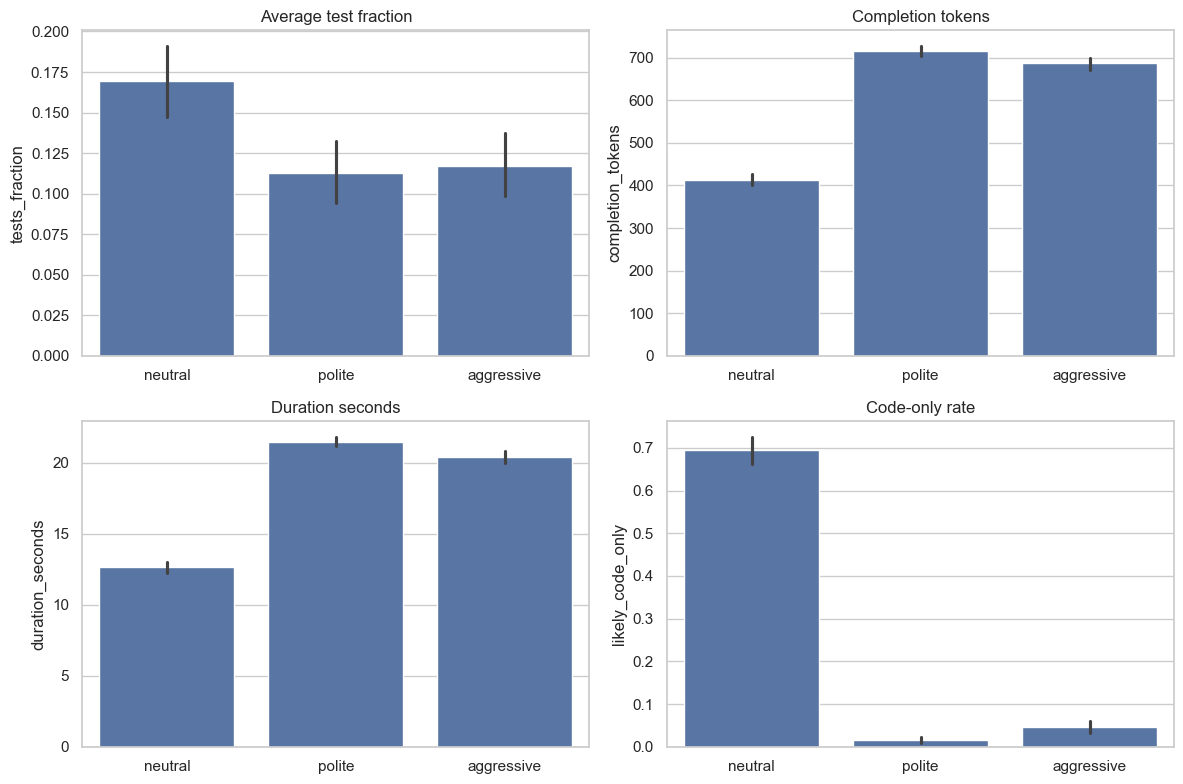

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    ("tests_fraction", "Average test fraction"),
    ("completion_tokens", "Completion tokens"),
    ("duration_seconds", "Duration seconds"),
    ("likely_code_only", "Code-only rate"),
]
for ax, (metric, title) in zip(axes.flat, plot_specs):
    sns.barplot(data=df, x="Tone", y=metric, errorbar=("ci", 95), ax=ax, order=["neutral", "polite", "aggressive"])
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

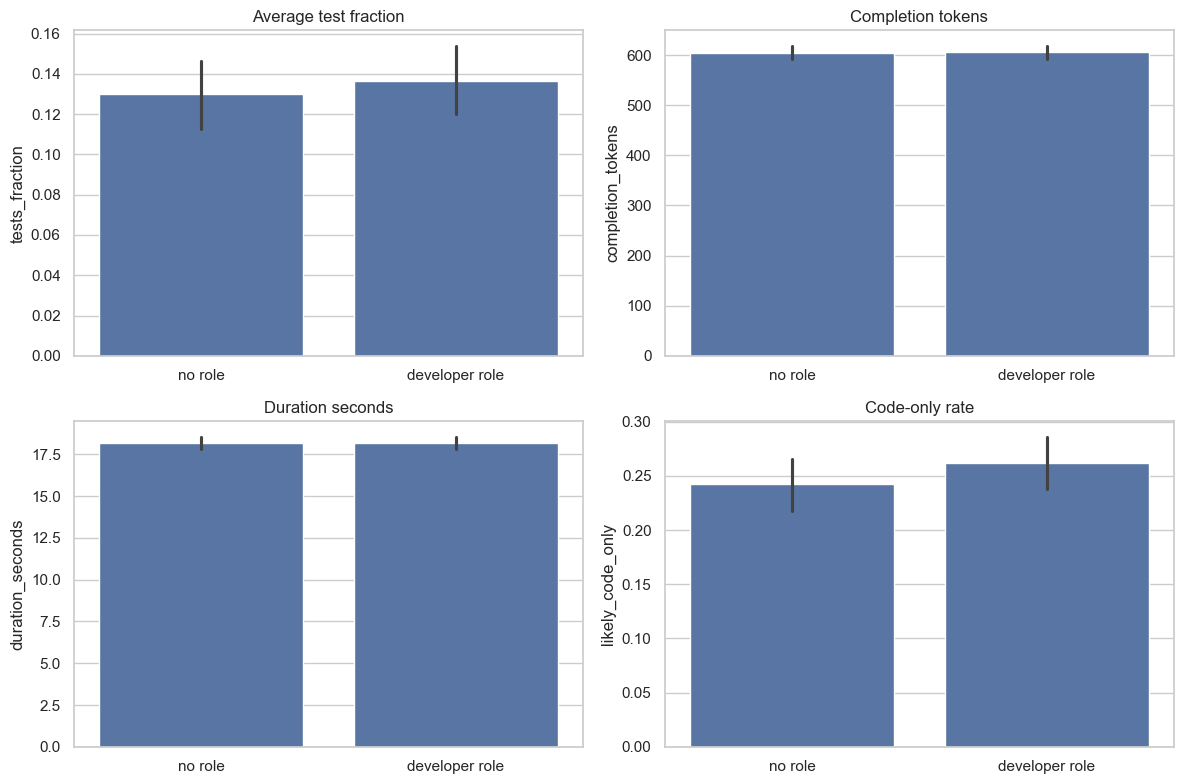

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    ("tests_fraction", "Average test fraction"),
    ("completion_tokens", "Completion tokens"),
    ("duration_seconds", "Duration seconds"),
    ("likely_code_only", "Code-only rate"),
]
for ax, (metric, title) in zip(axes.flat, plot_specs):
    sns.barplot(data=df, x="Role_framing", y=metric, errorbar=("ci", 95), ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

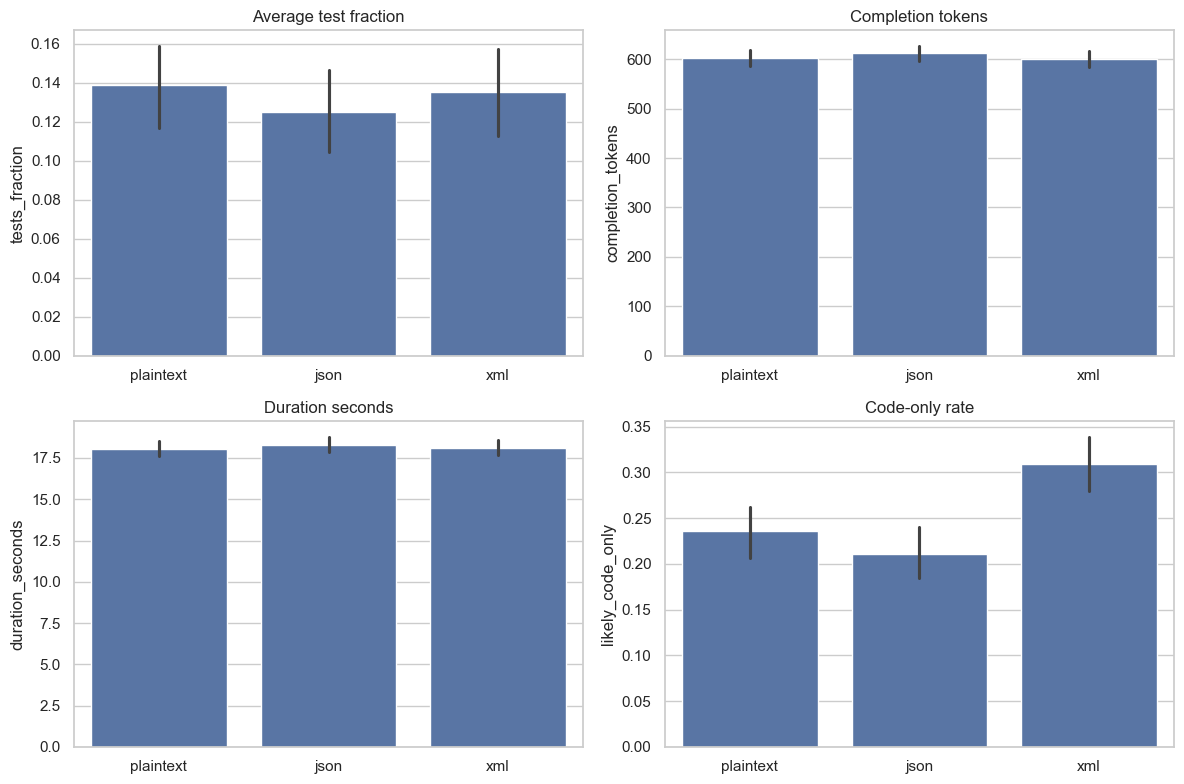

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    ("tests_fraction", "Average test fraction"),
    ("completion_tokens", "Completion tokens"),
    ("duration_seconds", "Duration seconds"),
    ("likely_code_only", "Code-only rate"),
]
for ax, (metric, title) in zip(axes.flat, plot_specs):
    sns.barplot(data=df, x="Format", y=metric, errorbar=("ci", 95), ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 7. Paired Prompt Effects

This compares factor levels within the same `(model, problem)` pair.

For tone, the reference level is the first template order, which is neutral. So polite/aggressive deltas are interpreted relative to neutral.

In [ ]:
def ordered_levels(data: pd.DataFrame, factor: str) -> list:
    template_order = (
        data[["template_id", factor]]
        .drop_duplicates()
        .sort_values("template_id")[factor]
        .dropna()
        .tolist()
    )
    seen = []
    for level in template_order:
        if level not in seen:
            seen.append(level)
    return seen


def paired_effects(data: pd.DataFrame, factor: str, metric: str, reference: object | None = None) -> pd.DataFrame:
    levels = ordered_levels(data, factor)
    if not levels:
        return pd.DataFrame()
    if reference is None:
        reference = levels[0]
    grouped = data.groupby(["model_short", "problem_id", factor], dropna=False)[metric].mean().reset_index()
    wide = grouped.pivot_table(index=["model_short", "problem_id"], columns=factor, values=metric, aggfunc="mean")
    rows = []
    for level in levels:
        if level == reference or level not in wide.columns or reference not in wide.columns:
            continue
        delta = (wide[level] - wide[reference]).dropna()
        n = len(delta)
        mean = delta.mean() if n else np.nan
        se = delta.std(ddof=1) / math.sqrt(n) if n > 1 else np.nan
        rows.append({
            "factor": factor, "metric": metric, "reference": reference, "level": level,
            "mean_delta": mean, "ci_low": mean - 1.96 * se if n > 1 else np.nan,
            "ci_high": mean + 1.96 * se if n > 1 else np.nan, "n_pairs": n,
        })
    return pd.DataFrame(rows)

paired_tables = []
for factor in technique_factors:
    for metric in summary_metrics:
        paired_tables.append(paired_effects(df, factor, metric))
paired_summary = pd.concat(paired_tables, ignore_index=True)
paired_summary.to_csv(OUTPUT_DIR / "paired_prompt_technique_effects.csv", index=False)
paired_summary[paired_summary["factor"].eq("Tone") & paired_summary["metric"].isin(["passed_int", "tests_fraction", "completion_tokens", "likely_code_only"])].style.format({"mean_delta": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}"})

,factor,metric,reference,level,mean_delta,ci_low,ci_high,n_pairs
0,Tone,passed_int,neutral,polite,-0.0367,-0.0683,-0.0050,150
1,Tone,passed_int,neutral,aggressive,-0.0344,-0.0638,-0.0051,150
2,Tone,tests_fraction,neutral,polite,-0.0563,-0.0906,-0.0221,150
3,Tone,tests_fraction,neutral,aggressive,-0.0525,-0.0818,-0.0233,150
6,Tone,completion_tokens,neutral,polite,+303.6511,+280.1903,+327.1120,150
7,Tone,completion_tokens,neutral,aggressive,+274.1333,+245.5586,+302.7080,150
8,Tone,likely_code_only,neutral,polite,-0.6789,-0.7239,-0.6339,150
9,Tone,likely_code_only,neutral,aggressive,-0.6489,-0.6983,-0.5994,150


## 8. Fixed-Effect Regression for Prompt Factors

This reruns the original fixed-effect regression:

```text
outcome ~ Tone + Role_framing + Format + model fixed effects + problem fixed effects
```

This controls for model ability and problem difficulty.

In [ ]:
def fit_fixed_effect(metric: str):
    factors = [f"C({factor})" for factor in technique_factors]
    rhs = " + ".join([*factors, "C(model_short)", "C(problem_id)"])
    formula = f"{metric} ~ {rhs}"
    model_data = df[[metric, "model_short", "problem_id", *technique_factors]].dropna()
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    return result, formula

regression_metrics = ["passed_int", "tests_fraction", "duration_seconds", "completion_tokens", "likely_code_only", "extra_text_ratio", "invalid_python_after_fix"]
regression_rows = []
regression_formulas = []
for metric in regression_metrics:
    result, formula = fit_fixed_effect(metric)
    params = result.params.rename("coef").to_frame()
    params["std_err"] = result.bse
    params["p_value"] = result.pvalues
    params["metric"] = metric
    params["term"] = params.index
    regression_rows.append(params.reset_index(drop=True))
    regression_formulas.append({"metric": metric, "formula": formula, "nobs": result.nobs, "rsquared": result.rsquared})
regression_table = pd.concat(regression_rows, ignore_index=True)
technique_terms = regression_table[regression_table["term"].str.contains("Tone|Role_framing|Format|Pressure", regex=True, na=False)].copy()
technique_terms.to_csv(OUTPUT_DIR / "fixed_effect_prompt_technique_models.csv", index=False)
pd.DataFrame(regression_formulas).to_csv(OUTPUT_DIR / "fixed_effect_prompt_technique_formulas.csv", index=False)
technique_terms.style.format({"coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"})

,coef,std_err,p_value,metric,term
1,+0.0344,0.0123,0.0050,passed_int,C(Tone)[T.neutral]
2,-0.0022,0.0119,0.8520,passed_int,C(Tone)[T.polite]
3,+0.0015,0.0099,0.8815,passed_int,C(Role_framing)[T.no role]
4,+0.0089,0.0120,0.4573,passed_int,C(Format)[T.plaintext]
5,+0.0100,0.0123,0.4153,passed_int,C(Format)[T.xml]
58,+0.0525,0.0133,0.0001,tests_fraction,C(Tone)[T.neutral]
59,-0.0038,0.0129,0.7670,tests_fraction,C(Tone)[T.polite]
60,-0.0065,0.0107,0.5481,tests_fraction,C(Role_framing)[T.no role]
61,+0.0140,0.0130,0.2828,tests_fraction,C(Format)[T.plaintext]
62,+0.0100,0.0132,0.4475,tests_fraction,C(Format)[T.xml]


## 9. Deep Behavior-Control Analysis

This is the professor's requested analysis.

We compare the baseline prompt model to models that add behavior controls:

- output length: `log_completion_tokens`
- code-only compliance: `likely_code_only`
- parsing/validity failure: `invalid_python_after_fix`
- runtime: `log_duration_seconds`

If the neutral-tone effect disappears after these controls, it suggests that tone works mainly by changing output behavior.

In [ ]:
def coef_rows(result, model_name: str, outcome: str) -> pd.DataFrame:
    rows = result.params.rename("coef").to_frame()
    rows["std_err"] = result.bse
    rows["p_value"] = result.pvalues
    rows["model_spec"] = model_name
    rows["outcome"] = outcome
    rows["term"] = rows.index
    return rows.reset_index(drop=True)


def fit_ols_behavior(outcome: str, controls: list[str], spec_name: str):
    prompt_terms = "C(Tone) + C(Role_framing) + C(Format)"
    fixed_effects = "C(model_short) + C(problem_id)"
    formula = f"{outcome} ~ " + " + ".join([prompt_terms, fixed_effects, *controls])
    model_cols = [outcome, "Tone", "Role_framing", "Format", "model_short", "problem_id", *controls]
    model_data = df[model_cols].dropna()
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    return result, formula

control_sets = {
    "M0_prompt_only": [],
    "M1_length": ["log_completion_tokens"],
    "M2_code_only": ["likely_code_only"],
    "M3_invalid_python": ["invalid_python_after_fix"],
    "M4_runtime": ["log_duration_seconds"],
    "M5_all_behavior_controls": ["log_completion_tokens", "likely_code_only", "invalid_python_after_fix", "log_duration_seconds"],
}

behavior_rows = []
behavior_formulas = []
for outcome in ["passed_int", "tests_fraction"]:
    for spec_name, controls in control_sets.items():
        result, formula = fit_ols_behavior(outcome, controls, spec_name)
        behavior_rows.append(coef_rows(result, spec_name, outcome))
        behavior_formulas.append({"outcome": outcome, "model_spec": spec_name, "formula": formula, "nobs": result.nobs, "rsquared": result.rsquared})
behavior_ols = pd.concat(behavior_rows, ignore_index=True)
behavior_ols.to_csv(OUTPUT_DIR / "behavior_control_ols_models.csv", index=False)
pd.DataFrame(behavior_formulas).to_csv(OUTPUT_DIR / "behavior_control_ols_formulas.csv", index=False)

focus_terms = ["C(Tone)[T.neutral]", "C(Tone)[T.polite]", "log_completion_tokens", "likely_code_only", "invalid_python_after_fix", "log_duration_seconds"]
focus_ols = behavior_ols[behavior_ols["term"].isin(focus_terms)].copy()
focus_ols.to_csv(OUTPUT_DIR / "focus_ols_terms.csv", index=False)
focus_ols[["outcome", "model_spec", "term", "coef", "std_err", "p_value"]].style.format({"coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"})

,outcome,model_spec,term,coef,std_err,p_value
1,passed_int,M0_prompt_only,C(Tone)[T.neutral],+0.0344,0.0123,0.0050
2,passed_int,M0_prompt_only,C(Tone)[T.polite],-0.0022,0.0119,0.8520
58,passed_int,M1_length,C(Tone)[T.neutral],-0.0266,0.0155,0.0859
59,passed_int,M1_length,C(Tone)[T.polite],+0.0040,0.0119,0.7357
114,passed_int,M1_length,log_completion_tokens,-0.1086,0.0198,0.0000
116,passed_int,M2_code_only,C(Tone)[T.neutral],+0.0083,0.0158,0.5996
117,passed_int,M2_code_only,C(Tone)[T.polite],-0.0010,0.0119,0.9321
172,passed_int,M2_code_only,likely_code_only,+0.0403,0.0171,0.0187
174,passed_int,M3_invalid_python,C(Tone)[T.neutral],+0.0343,0.0123,0.0051
175,passed_int,M3_invalid_python,C(Tone)[T.polite],-0.0025,0.0119,0.8352


## 10. Logistic Robustness Check

Because `passed_int` is binary, this reruns the behavior-control models with a binomial GLM/logit link.

In [ ]:
def fit_glm_binomial(controls: list[str], spec_name: str):
    prompt_terms = "C(Tone) + C(Role_framing) + C(Format)"
    fixed_effects = "C(model_short) + C(problem_id)"
    formula = "passed_int ~ " + " + ".join([prompt_terms, fixed_effects, *controls])
    model_cols = ["passed_int", "Tone", "Role_framing", "Format", "model_short", "problem_id", *controls]
    model_data = df[model_cols].dropna()
    result = smf.glm(formula=formula, data=model_data, family=sm.families.Binomial()).fit(cov_type="HC3")
    return result, formula

glm_rows = []
glm_formulas = []
for spec_name, controls in control_sets.items():
    result, formula = fit_glm_binomial(controls, spec_name)
    glm_rows.append(coef_rows(result, spec_name, "passed_int_glm_binomial_logit"))
    glm_formulas.append({"outcome": "passed_int", "model_spec": spec_name, "formula": formula, "nobs": result.nobs, "aic": result.aic})
glm_results = pd.concat(glm_rows, ignore_index=True)
glm_results.to_csv(OUTPUT_DIR / "behavior_control_glm_logit_models.csv", index=False)
pd.DataFrame(glm_formulas).to_csv(OUTPUT_DIR / "behavior_control_glm_formulas.csv", index=False)
focus_glm = glm_results[glm_results["term"].isin(focus_terms)].copy()
focus_glm.to_csv(OUTPUT_DIR / "focus_glm_terms.csv", index=False)
focus_glm[["model_spec", "term", "coef", "std_err", "p_value"]].style.format({"coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"})

,model_spec,term,coef,std_err,p_value
1,M0_prompt_only,C(Tone)[T.neutral],+0.5347,0.1839,0.0036
2,M0_prompt_only,C(Tone)[T.polite],-0.0393,0.2028,0.8465
58,M1_length,C(Tone)[T.neutral],-0.4004,0.2754,0.1461
59,M1_length,C(Tone)[T.polite],+0.0630,0.2040,0.7574
114,M1_length,log_completion_tokens,-1.4298,0.2868,0.0000
116,M2_code_only,C(Tone)[T.neutral],+0.0980,0.3094,0.7513
117,M2_code_only,C(Tone)[T.polite],-0.0283,0.2020,0.8888
172,M2_code_only,likely_code_only,+0.5788,0.3023,0.0555
174,M3_invalid_python,C(Tone)[T.neutral],+0.5303,0.1840,0.0039
175,M3_invalid_python,C(Tone)[T.polite],-0.0447,0.2029,0.8255


## 11. Model-Specific and Difficulty Analyses

These checks prevent overclaiming.

They answer:

- Is neutral tone best for every model?
- Does tone help equally on hard, medium, and easy problems?

In [ ]:
model_tone = (
    df.groupby(["model_short", "Tone"])
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python_after_fix", "mean"),
        runtime_failure_rate=("runtime_failure", "mean"),
    )
    .reset_index()
    .sort_values(["model_short", "tests_fraction"], ascending=[True, False])
)
model_tone.to_csv(OUTPUT_DIR / "model_by_tone_behavior_summary.csv", index=False)
model_tone.style.format({"pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_completion_tokens": "{:.0f}", "avg_duration_seconds": "{:.2f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}", "runtime_failure_rate": "{:.1%}"})

,model_short,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,runtime_failure_rate
1,gemma2-9b,neutral,300,10.0%,18.0%,382,12.73,77.7%,0.0%,31.3%
0,gemma2-9b,aggressive,300,9.3%,12.8%,682,22.00,0.0%,0.0%,42.7%
2,gemma2-9b,polite,300,9.0%,11.4%,739,23.96,0.0%,0.0%,50.0%
4,llama3.1-8b,neutral,300,7.0%,11.8%,462,13.59,51.7%,0.7%,46.0%
5,llama3.1-8b,polite,300,4.7%,7.8%,635,18.44,4.7%,0.0%,64.0%
3,llama3.1-8b,aggressive,300,4.3%,7.0%,588,16.97,12.7%,0.3%,65.3%
7,qwen2.5-7b,neutral,300,18.3%,21.1%,394,11.54,79.0%,0.0%,30.0%
6,qwen2.5-7b,aggressive,300,11.3%,15.3%,790,22.23,1.0%,1.0%,42.3%
8,qwen2.5-7b,polite,300,10.7%,14.7%,775,22.00,0.0%,0.0%,48.7%


In [ ]:
problem_difficulty = (
    df.groupby("problem_id")
    .agg(problem_mean_tests_fraction=("tests_fraction", "mean"), problem_pass_rate=("passed_int", "mean"))
    .reset_index()
)
problem_difficulty["difficulty_band"] = pd.qcut(problem_difficulty["problem_mean_tests_fraction"], q=3, labels=["hard", "medium", "easy"], duplicates="drop")
df = df.drop(columns=["difficulty_band"], errors="ignore").merge(problem_difficulty[["problem_id", "difficulty_band"]], on="problem_id", how="left")

difficulty_tone = (
    df.groupby(["difficulty_band", "Tone"], observed=False)
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python_after_fix", "mean"),
        runtime_failure_rate=("runtime_failure", "mean"),
    )
    .reset_index()
)
difficulty_tone.to_csv(OUTPUT_DIR / "difficulty_by_tone_behavior_summary.csv", index=False)
difficulty_tone.style.format({"pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_completion_tokens": "{:.0f}", "avg_duration_seconds": "{:.2f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}", "runtime_failure_rate": "{:.1%}"})

,difficulty_band,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,invalid_python_rate,runtime_failure_rate
0,hard,aggressive,306,0.0%,0.1%,745,21.94,3.3%,1.0%,74.8%
1,hard,neutral,306,0.0%,0.6%,445,13.56,62.7%,0.0%,69.9%
2,hard,polite,306,0.0%,0.1%,745,22.26,1.0%,0.0%,76.1%
3,medium,aggressive,288,2.8%,7.0%,647,19.30,4.9%,0.0%,40.6%
4,medium,neutral,288,6.6%,12.2%,391,12.03,71.5%,0.7%,24.7%
5,medium,polite,288,3.8%,5.6%,683,20.54,0.7%,0.0%,43.1%
6,easy,aggressive,306,21.9%,27.7%,667,19.89,5.6%,0.3%,34.3%
7,easy,neutral,306,28.4%,37.8%,400,12.24,74.2%,0.0%,12.1%
8,easy,polite,306,20.3%,27.9%,718,21.55,2.9%,0.0%,42.8%


## 12. Error Categories and Behavior Correlations

These tables help explain the mechanism behind tone effects.

In [ ]:
error_summary = (
    df.groupby(["Tone", "error_category"])
    .size()
    .rename("runs")
    .reset_index()
)
error_summary["rate"] = error_summary["runs"] / error_summary.groupby("Tone")["runs"].transform("sum")
error_summary = error_summary.sort_values(["Tone", "runs"], ascending=[True, False])
error_summary.to_csv(OUTPUT_DIR / "tone_error_category_summary.csv", index=False)
error_summary.style.format({"rate": "{:.1%}"})

,Tone,error_category,runs,rate
2,aggressive,name_not_defined,432,48.0%
6,aggressive,wrong_answer,374,41.6%
3,aggressive,none,75,8.3%
5,aggressive,timeout,9,1.0%
4,aggressive,syntax_error,5,0.6%
1,aggressive,invalid_python_response,4,0.4%
0,aggressive,import_error,1,0.1%
12,neutral,wrong_answer,472,52.4%
8,neutral,name_not_defined,306,34.0%
9,neutral,none,106,11.8%


In [ ]:
corr_cols = ["passed_int", "tests_fraction", "completion_tokens", "duration_seconds", "likely_code_only", "invalid_python_after_fix", "runtime_failure", "extra_text_ratio"]
correlations = df[corr_cols].corr(method="pearson")
correlations.to_csv(OUTPUT_DIR / "behavior_metric_correlations.csv")
correlations.style.format("{:.3f}").background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,passed_int,tests_fraction,completion_tokens,duration_seconds,likely_code_only,invalid_python_after_fix,runtime_failure,extra_text_ratio
passed_int,1.000,0.885,-0.106,-0.102,0.091,-0.015,-0.302,-0.109
tests_fraction,0.885,1.000,-0.129,-0.123,0.120,-0.020,-0.391,-0.147
completion_tokens,-0.106,-0.129,1.000,0.985,-0.568,0.099,0.176,0.493
duration_seconds,-0.102,-0.123,0.985,1.000,-0.568,0.090,0.166,0.495
likely_code_only,0.091,0.120,-0.568,-0.568,1.000,0.081,-0.218,-0.760
invalid_python_after_fix,-0.015,-0.020,0.099,0.090,0.081,1.000,0.050,-0.065
runtime_failure,-0.302,-0.391,0.176,0.166,-0.218,0.050,1.000,0.254
extra_text_ratio,-0.109,-0.147,0.493,0.495,-0.760,-0.065,0.254,1.000


## 13. Best and Worst Templates

This reruns the original template-level summary using fixed-extractor results.

In [ ]:
template_summary = (
    df.groupby(["template_id", *technique_factors])
    .agg(
        runs=("task_id", "size"),
        models=("model_short", "nunique"),
        problems=("problem_id", "nunique"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        invalid_python_rate=("invalid_python_after_fix", "mean"),
    )
    .reset_index()
    .sort_values(["tests_fraction", "pass_rate"], ascending=False)
)
template_summary.to_csv(OUTPUT_DIR / "prompt_template_summary.csv", index=False)
print("Best templates")
display(template_summary.head(8).style.format({"pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_duration_seconds": "{:.2f}", "avg_completion_tokens": "{:.0f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}"}))
print("Worst templates")
display(template_summary.tail(8).style.format({"pass_rate": "{:.1%}", "tests_fraction": "{:.1%}", "avg_duration_seconds": "{:.2f}", "avg_completion_tokens": "{:.0f}", "code_only_rate": "{:.1%}", "invalid_python_rate": "{:.1%}"}))

Best templates


,template_id,Tone,Role_framing,Format,runs,models,problems,pass_rate,tests_fraction,avg_duration_seconds,avg_completion_tokens,code_only_rate,invalid_python_rate
5,6,neutral,developer role,xml,150,3,50,15.3%,19.7%,12.97,421,81.3%,0.7%
4,5,neutral,developer role,json,150,3,50,13.3%,18.7%,13.13,431,57.3%,0.0%
0,1,neutral,no role,plaintext,150,3,50,13.3%,18.4%,12.28,400,58.0%,0.0%
3,4,neutral,developer role,plaintext,150,3,50,10.7%,18.1%,12.19,400,78.0%,0.0%
2,3,neutral,no role,xml,150,3,50,11.3%,15.2%,12.09,393,83.3%,0.7%
6,7,polite,no role,plaintext,150,3,50,9.3%,14.5%,20.52,682,2.0%,0.0%
16,17,aggressive,developer role,json,150,3,50,9.3%,13.8%,19.68,664,2.0%,0.0%
8,9,polite,no role,xml,150,3,50,10.0%,13.0%,21.51,717,0.7%,0.0%


Worst templates


,template_id,Tone,Role_framing,Format,runs,models,problems,pass_rate,tests_fraction,avg_duration_seconds,avg_completion_tokens,code_only_rate,invalid_python_rate
1,2,neutral,no role,json,150,3,50,6.7%,11.5%,13.08,430,58.7%,0.0%
7,8,polite,no role,json,150,3,50,9.3%,10.9%,21.82,728,1.3%,0.0%
14,15,aggressive,no role,xml,150,3,50,8.0%,10.9%,20.36,682,8.0%,0.7%
9,10,polite,developer role,plaintext,150,3,50,7.3%,10.1%,21.37,713,2.7%,0.0%
13,14,aggressive,no role,json,150,3,50,7.3%,10.1%,20.51,693,5.3%,1.3%
10,11,polite,developer role,json,150,3,50,6.7%,10.1%,21.68,725,2.0%,0.0%
15,16,aggressive,developer role,plaintext,150,3,50,7.3%,9.9%,20.78,701,0.0%,0.0%
11,12,polite,developer role,xml,150,3,50,6.0%,9.3%,21.91,732,0.7%,0.0%
